# D04 — Module de risque : ARCH-LM · GARCH · volatilité prévue · VaR / ES

**Projet :** Quant Lab B09 — DIA

D03 a montré que la moyenne des rendements du DIA est quasi imprévisible, mais que leurs carrés sont fortement autocorrélés (effet ARCH) et que leur loi a des queues épaisses. D04 modélise donc le **risque**, pas la direction. Toute la logique est dans `src/risk.py` et `src/risk_backtest.py` ; ce notebook importe, affiche et trace.

> **Protocole anti-fuite**
> - Paramètres estimés sur l'**apprentissage seul** (2018–2022), puis **gelés** : `arch_model(r_full, ...).fix(params)`, sans ré-estimation.
> - Prévision à **un pas** : la valeur rangée à la date cible t+1 n'utilise que l'information disponible à la clôture t (colonnes `date_prevision`, `date_cible`).
> - Règle de choix **fixée avant** : modèle retenu = plus petit AIC d'apprentissage. La validation (2023–2024) sert à confirmer ; le test (2025–2026) est lu une seule fois.
> - Les baselines (EWMA, écart-type glissant, simulation historique) n'utilisent que des données ≤ t.
>
> **Unités**
> - Rendements r en **% par jour** (100 × rendement log journalier).
> - Volatilité σ en **% par jour** ; annualisée = σ × √252, toujours écrit explicitement.
> - VaR et ES : **perte positive en % par jour**, sur une séance, et en **USD** sur un capital de 100 000 $.
> - Variances réalisées et prévues en %² par jour.

In [1]:
import os
import sys
import warnings
from pathlib import Path

# --- Trouver la racine du projet (contient configs/frozen.yaml) ---
_candidate = Path.cwd()
for _ in range(6):
    if (_candidate / 'configs' / 'frozen.yaml').exists():
        break
    _candidate = _candidate.parent
else:
    raise RuntimeError('Racine du projet introuvable depuis ' + str(Path.cwd()))
root = _candidate
os.chdir(str(root))
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
# -----------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from src.data import load_closes, load_ohlcv
from src.features import build_frame, split
from src.models.econometrics import fit_state_space, select_arima_order
from src.risk import (
    correlation_levier, diagnostics_residus_std, fenetres, fit_grid, historical_sigma,
    load_risk_model, mesure_ewma, mesure_historique, mesure_parametrique, modele_retenu,
    parkinson_sigma, qq_points, rendements_pct, residus_standardises, resume_modele,
    resume_var_moyenne, risk_today, rolling_sigma, save_risk_model, tableau_arch_lm,
    tableau_parametres, tableau_risque_date, tableau_temps,
)
from src.risk_backtest import tableau_dm_volatilite, tableau_verification, tableau_volatilite

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', lambda x: f'{x:.4g}')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

with open(root / 'configs' / 'frozen.yaml', encoding='utf-8') as fh:
    CFG = yaml.safe_load(fh)
RCFG = CFG['risk']
CAPITAL = RCFG['capital']

REP_D04 = root / 'reports' / 'd04'
REP_FIG = REP_D04 / 'figures'
REP_FIG.mkdir(parents=True, exist_ok=True)

print('Imports OK')
print('  Rapports :', REP_D04.relative_to(root))
print('  Figures  :', REP_FIG.relative_to(root))
print('  Paramètres risque (frozen.yaml) :', RCFG)

Imports OK
  Rapports : reports\d04
  Figures  : reports\d04\figures
  Paramètres risque (frozen.yaml) : {'scale': 100, 'alphas': [0.05, 0.01], 'models': [{'name': 'GARCH', 'vol': 'GARCH', 'p': 1, 'o': 0, 'q': 1}, {'name': 'GJR-GARCH', 'vol': 'GARCH', 'p': 1, 'o': 1, 'q': 1}, {'name': 'EGARCH', 'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 1}], 'distributions': ['normal', 't', 'skewt'], 'ewma_lambda': 0.94, 'hs_window': 250, 'rolling_window': 20, 'capital': 100000, 'es_n_sim': 5000, 'seuil_tests': 0.05}


In [2]:
closes = load_closes()
r = rendements_pct(closes)          # % par jour ; la dernière séance du snapshot est conservée
w = fenetres(r)                     # bornes lues dans frozen.yaml
fen_idx = {'validation': w['validation'].index, 'test': w['test'].index}

ohlcv = load_ohlcv()
dia = ohlcv[ohlcv['ticker'] == CFG['tickers']['asset']].set_index('date').sort_index()
sigma_park = parkinson_sigma(dia['high'], dia['low'])   # volatilité RÉALISÉE, % par jour

display(pd.DataFrame([
    {'fenetre': k, 'premiere date cible': v.index[0].date(), 'derniere date cible': v.index[-1].date(),
     'seances': len(v)}
    for k, v in w.items()
]))

,fenetre,premiere date cible,derniere date cible,seances
0,train,2018-01-03,2022-12-30,1258
1,validation,2023-01-03,2024-12-31,502
2,test,2025-01-02,2026-10-30,459


## 1. Effet ARCH — test ARCH-LM (Engle, 1982)

**H0** : pas d'effet ARCH (variance conditionnelle constante). Régression de x²_t sur ses 5 ou 10 retards ; LM = n·R² ~ χ²(retards).
Le test porte sur la fenêtre d'**apprentissage**, pour deux séries : les rendements centrés, et les résidus de l'ARIMA retenu en D03 (même règle AIC, même fenêtre).

In [3]:
frame = build_frame(closes)
dec = split(frame)
train_mask = pd.Series(False, index=frame.index)
train_mask.loc[dec['train'].index] = True
ordre_arima = select_arima_order(frame, train_mask)
res_arima = fit_state_space(frame, train_mask, order=ordre_arima)
print('ARIMA retenu en D03 (plus petit AIC sur l’apprentissage) :', res_arima.nom)

df_arch = tableau_arch_lm({
    'Rendements centrés (apprentissage, %)': w['train'] - w['train'].mean(),
    'Résidus ' + res_arima.nom + ' (apprentissage, %)': 100 * res_arima.residuals,
}, lags=(5, 10))
display(df_arch)

ARIMA retenu en D03 (plus petit AIC sur l’apprentissage) : ARIMA(0,0,3)


,serie,retards,stat_lm,p_value,n,conclusion
0,"Rendements centrés (apprentissage, %)",5,461.2,1.867e-97,1258,H0 rejetée au seuil 5% : effet ARCH présent
1,"Rendements centrés (apprentissage, %)",10,515.1,2.559e-104,1258,H0 rejetée au seuil 5% : effet ARCH présent
2,"Résidus ARIMA(0,0,3) (apprentissage, %)",5,315.6,4.523e-66,1248,H0 rejetée au seuil 5% : effet ARCH présent
3,"Résidus ARIMA(0,0,3) (apprentissage, %)",10,406.3,4.275e-81,1248,H0 rejetée au seuil 5% : effet ARCH présent


## 2. Asymétrie et grille 3 modèles × 3 lois (apprentissage)

Une baisse est suivie d'une volatilité plus forte qu'une hausse de même taille : sur l'apprentissage, la corrélation entre r_t et |r_{t+1}| vaut −0.1129 (p = 5.99e-05, première ligne affichée ci-dessous). Cette asymétrie justifie de comparer au GARCH(1,1) symétrique le GJR-GARCH(1,1,1) et l'EGARCH(1,1,1), chacun avec trois lois standardisées : normale, Student t et Student asymétrique (skewt, Hansen 1994).

**Règle fixée avant de regarder la validation et le test** : modèle retenu = plus petit AIC d'apprentissage parmi les modèles convergés. Le **GARCH(1,1) normal**, référence du cahier, reste dans toutes les comparaisons.

In [4]:
levier = correlation_levier(w['train'])
print('Effet de levier (apprentissage) : corr(r_t, |r_t+1|) = {:.4g} (p = {:.4g}) ; '
      '|r_t+1| moyen = {:.4g} % après une baisse, {:.4g} % après une hausse'.format(
          levier['corr_r_absr_suivant'], levier['pval_absr'],
          levier['absr_moyen_apres_baisse_pct'], levier['absr_moyen_apres_hausse_pct']))

grille, fits = fit_grid(w['train'], CFG)
display(grille[['modele', 'famille', 'loi', 'aic', 'bic', 'loglik', 'temps_estimation_s', 'converge']]
        .rename(columns={'temps_estimation_s': 'temps estimation (s)'}))

NOM_RETENU = modele_retenu(grille)
NOM_REF = 'GARCH-normal'     # GARCH(1,1) à loi normale, référence du cahier
fit_ret, fit_ref = fits[NOM_RETENU], fits[NOM_REF]
print('Modèle retenu (plus petit AIC sur l’apprentissage) :', NOM_RETENU)
print('Référence du cahier                               :', NOM_REF)

Effet de levier (apprentissage) : corr(r_t, |r_t+1|) = -0.1129 (p = 5.99e-05) ; |r_t+1| moyen = 0.9708 % après une baisse, 0.779 % après une hausse


,modele,famille,loi,aic,bic,loglik,temps estimation (s),converge
0,EGARCH-skewt,EGARCH,skewt,3502,3537,-1744,0.04703,True
1,GJR-GARCH-skewt,GJR-GARCH,skewt,3509,3545,-1748,0.05358,True
2,EGARCH-t,EGARCH,t,3525,3555,-1756,0.02656,True
3,GJR-GARCH-t,GJR-GARCH,t,3528,3559,-1758,0.03532,True
4,GARCH-skewt,GARCH,skewt,3542,3573,-1765,0.04256,True
5,GARCH-t,GARCH,t,3557,3583,-1773,0.02938,True
6,EGARCH-normal,EGARCH,normal,3585,3610,-1787,0.02248,True
7,GJR-GARCH-normal,GJR-GARCH,normal,3591,3617,-1791,0.02471,True
8,GARCH-normal,GARCH,normal,3622,3643,-1807,0.02016,True


Modèle retenu (plus petit AIC sur l’apprentissage) : EGARCH-skewt
Référence du cahier                               : GARCH-normal


## 3. Lecture du modèle retenu

- **α** : réaction de la volatilité à un choc de la veille ; **β** : mémoire de la volatilité ; **γ** : asymétrie (dans l'EGARCH d'arch, γ < 0 signifie qu'un choc négatif augmente davantage la volatilité ; dans le GJR, c'est γ > 0) ; **ν / η** : degrés de liberté (plus petit = queues plus épaisses) ; **λ** : asymétrie de la loi (λ < 0 = queue gauche plus lourde).
- Persistance : GARCH = α+β ; GJR = α+β+γ/2 ; EGARCH = β. Demi-vie d'un choc = ln 0,5 / ln(persistance), en séances.
- Volatilité de long terme de l'EGARCH : niveau géométrique exp(E[ln σ²]/2), avec la correction E|z| propre à la loi ; sa variance inconditionnelle n'existe pas sous t / skewt (voir docstring de `vol_long_terme`). La volatilité conditionnelle moyenne sur l'apprentissage sert de contrôle.

In [5]:
print('Modèle retenu :', NOM_RETENU)
display(tableau_parametres(fit_ret))
display(resume_modele(fit_ret))

print('Référence :', NOM_REF)
display(tableau_parametres(fit_ref))
display(resume_modele(fit_ref))

print('Persistance et niveaux de long terme de toute la grille :')
display(grille[['modele', 'persistance', 'demi_vie_seances', 'vol_lt_pct_jour', 'vol_lt_annuelle_pct',
                'vol_moyenne_apprentissage_pct']]
        .rename(columns={'demi_vie_seances': 'demi-vie (séances)',
                         'vol_lt_pct_jour': 'σ long terme (% par jour)',
                         'vol_lt_annuelle_pct': 'σ long terme × √252 (% par an)',
                         'vol_moyenne_apprentissage_pct': 'σ moyenne apprentissage (% par jour)'}))

Modèle retenu : EGARCH-skewt


,parametre,valeur,p_value,role,unite
0,mu,0.0196,0.3908,moyenne conditionnelle,% par jour
1,omega,0.008404,0.315,constante de variance,%² par jour (EGARCH : ln %²)
2,alpha[1],0.1814,0.0004062,réaction aux chocs,sans unité
3,gamma[1],-0.1694,1.447e-16,asymétrie (effet de levier),sans unité
4,beta[1],0.9728,0,mémoire de la volatilité,sans unité
5,eta,6.851,3.632e-08,degrés de liberté (queues épaisses),sans unité
6,lambda,-0.2049,6.826e-07,asymétrie de la loi (Hansen),sans unité


,indicateur,valeur,unite
0,persistance,0.9728,sans unité
1,demi-vie d'un choc,25.11,séances
2,volatilité de long terme,1.025,% par jour
3,volatilité de long terme annualisée (× √252),16.26,% par an
4,volatilité conditionnelle moyenne (apprentissage),1.343,% par jour
5,volatilité conditionnelle moyenne annualisée (× √252),21.33,% par an


Référence : GARCH-normal


,parametre,valeur,p_value,role,unite
0,mu,0.07701,0.0008843,moyenne conditionnelle,% par jour
1,omega,0.05829,0.0004172,constante de variance,%² par jour (EGARCH : ln %²)
2,alpha[1],0.2105,5.824e-09,réaction aux chocs,sans unité
3,beta[1],0.7601,1.647e-135,mémoire de la volatilité,sans unité


,indicateur,valeur,unite
0,persistance,0.9706,sans unité
1,demi-vie d'un choc,23.22,séances
2,volatilité de long terme,1.408,% par jour
3,volatilité de long terme annualisée (× √252),22.35,% par an
4,volatilité conditionnelle moyenne (apprentissage),1.379,% par jour
5,volatilité conditionnelle moyenne annualisée (× √252),21.89,% par an


Persistance et niveaux de long terme de toute la grille :


,modele,persistance,demi-vie (séances),σ long terme (% par jour),σ long terme × √252 (% par an),σ moyenne apprentissage (% par jour)
0,EGARCH-skewt,0.9728,25.11,1.025,16.26,1.343
1,GJR-GARCH-skewt,0.9834,41.37,1.41,22.38,1.436
2,EGARCH-t,0.969,21.98,0.9071,14.4,1.346
3,GJR-GARCH-t,0.9793,33.14,1.318,20.92,1.439
4,GARCH-skewt,0.9848,45.22,1.551,24.63,1.389
5,GARCH-t,0.9876,55.41,1.845,29.29,1.408
6,EGARCH-normal,0.9502,13.57,1.13,17.93,1.322
7,GJR-GARCH-normal,0.9771,29.94,1.439,22.84,1.432
8,GARCH-normal,0.9706,23.22,1.408,22.35,1.379


## 4. Diagnostics des résidus standardisés z (apprentissage)

z_t = (r_t − μ) / σ_t, sans unité. Si le modèle est bien spécifié, z ne doit plus montrer d'autocorrélation (Ljung-Box z), ni d'effet ARCH (Ljung-Box z², ARCH-LM). Jarque-Bera teste la **normalité** : un rejet est attendu si la loi retenue n'est pas normale ; c'est le QQ-plot contre la loi retenue qui juge l'adéquation de la loi.

,test,retards,stat,p_value,conclusion
0,Ljung-Box z,5,2.055,0.8415,H0 non rejetée
1,Ljung-Box z,10,13.06,0.2205,H0 non rejetée
2,Ljung-Box z,20,17.21,0.6391,H0 non rejetée
3,Ljung-Box z²,5,17.87,0.003108,H0 rejetée
4,Ljung-Box z²,10,19.25,0.03719,H0 rejetée
5,Ljung-Box z²,20,23.41,0.2693,H0 non rejetée
6,ARCH-LM z,5,17.09,0.004325,H0 rejetée
7,ARCH-LM z,10,18.84,0.04234,H0 rejetée
8,Jarque-Bera z,NaN,495.1,3.163e-108,H0 rejetée


Asymétrie de z : -0.808 | kurtosis de z (loi normale = 3) : 5.614


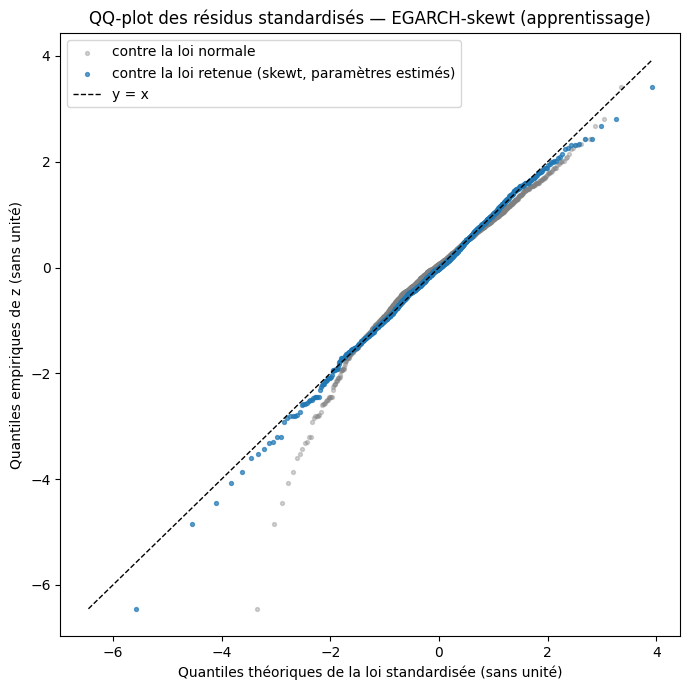

Figure sauvegardée : reports\d04\figures\qqplot_residus_std.png


In [6]:
z = residus_standardises(fit_ret['spec'], fit_ret['params'], w['train'])
diag_z = diagnostics_residus_std(z)
display(diag_z)
print('Asymétrie de z :', round(diag_z.attrs['asymetrie'], 3),
      '| kurtosis de z (loi normale = 3) :', round(diag_z.attrs['kurtosis'], 3))

qq = qq_points(z, fit_ret['spec']['dist'], fit_ret['params'])
qq_n = qq_points(z, 'normal', {})
bornes = [min(qq.min().min(), qq_n.min().min()), max(qq.max().max(), qq_n.max().max())]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(qq_n['theorique'], qq_n['empirique'], s=8, alpha=0.35, color='grey',
           label='contre la loi normale')
ax.scatter(qq['theorique'], qq['empirique'], s=8, alpha=0.7, color='#1f77b4',
           label='contre la loi retenue (' + fit_ret['spec']['dist'] + ', paramètres estimés)')
ax.plot(bornes, bornes, 'k--', lw=1, label='y = x')
ax.set_xlabel('Quantiles théoriques de la loi standardisée (sans unité)')
ax.set_ylabel('Quantiles empiriques de z (sans unité)')
ax.set_title('QQ-plot des résidus standardisés — ' + NOM_RETENU + ' (apprentissage)')
ax.legend(loc='upper left')
plt.tight_layout()
fig.savefig(REP_FIG / 'qqplot_residus_std.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figure sauvegardée :', (REP_FIG / 'qqplot_residus_std.png').relative_to(root))

## 5. Volatilité prévue contre volatilité réalisée (validation + test)

σ prévue à un pas, paramètres gelés, contre deux mesures **réalisées** le jour cible : |r| (bruitée) et la volatilité de Parkinson (1980), σ² = (ln H/L)² / (4 ln 2), plus précise mais qui ignore l'écart de nuit (clôture → ouverture) et est donc structurellement plus basse que l'écart-type clôture-à-clôture. Toutes les courbes sont en % par jour. La ligne pointillée marque le début du test.

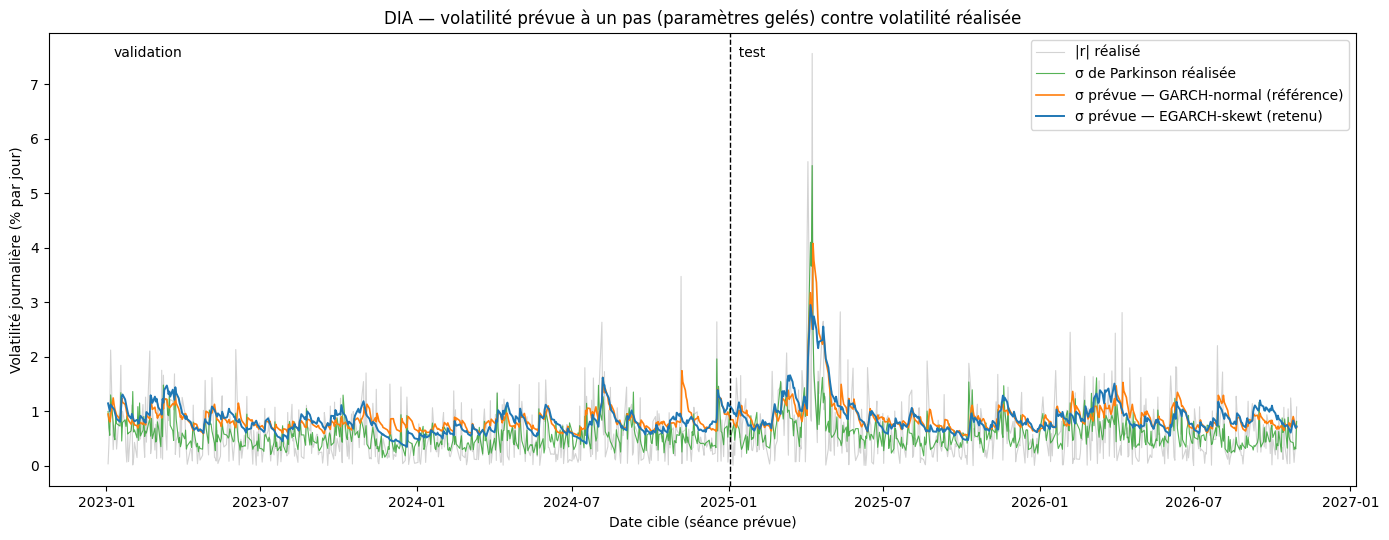

Figure sauvegardée : reports\d04\figures\volatilite_prevue.png


In [7]:
m_ret = mesure_parametrique(r, fit_ret)
m_ref = mesure_parametrique(r, fit_ref)
m_ewma = mesure_ewma(r)
m_hs = mesure_historique(r)

idx_vt = fen_idx['validation'].append(fen_idx['test'])
debut_test = fen_idx['test'][0]

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(idx_vt, r.reindex(idx_vt).abs(), color='lightgrey', lw=0.8, label='|r| réalisé')
ax.plot(idx_vt, sigma_park.reindex(idx_vt), color='#2ca02c', lw=0.8, alpha=0.8,
        label='σ de Parkinson réalisée')
ax.plot(idx_vt, m_ref['serie']['sigma_pct'].reindex(idx_vt), color='#ff7f0e', lw=1.2,
        label='σ prévue — ' + NOM_REF + ' (référence)')
ax.plot(idx_vt, m_ret['serie']['sigma_pct'].reindex(idx_vt), color='#1f77b4', lw=1.4,
        label='σ prévue — ' + NOM_RETENU + ' (retenu)')
ax.axvline(debut_test, color='black', ls='--', lw=1)
ax.text(fen_idx['validation'][5], 0.97, 'validation', transform=ax.get_xaxis_transform(), va='top')
ax.text(debut_test, 0.97, '  test', transform=ax.get_xaxis_transform(), va='top')
ax.set_xlabel('Date cible (séance prévue)')
ax.set_ylabel('Volatilité journalière (% par jour)')
ax.set_title('DIA — volatilité prévue à un pas (paramètres gelés) contre volatilité réalisée')
ax.legend(loc='upper right')
plt.tight_layout()
fig.savefig(REP_FIG / 'volatilite_prevue.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figure sauvegardée :', (REP_FIG / 'volatilite_prevue.png').relative_to(root))

## 6. VaR et ES à 95 % et 99 % — violations

Rendement réalisé, −VaR et −ES prévues par le modèle retenu (en % par jour, sur une séance). Une **violation** est un jour où la perte dépasse la VaR (r < −VaR) ; elles sont en rouge. Sous un modèle correct, on attend 5 % de violations à 95 % et 1 % à 99 %.

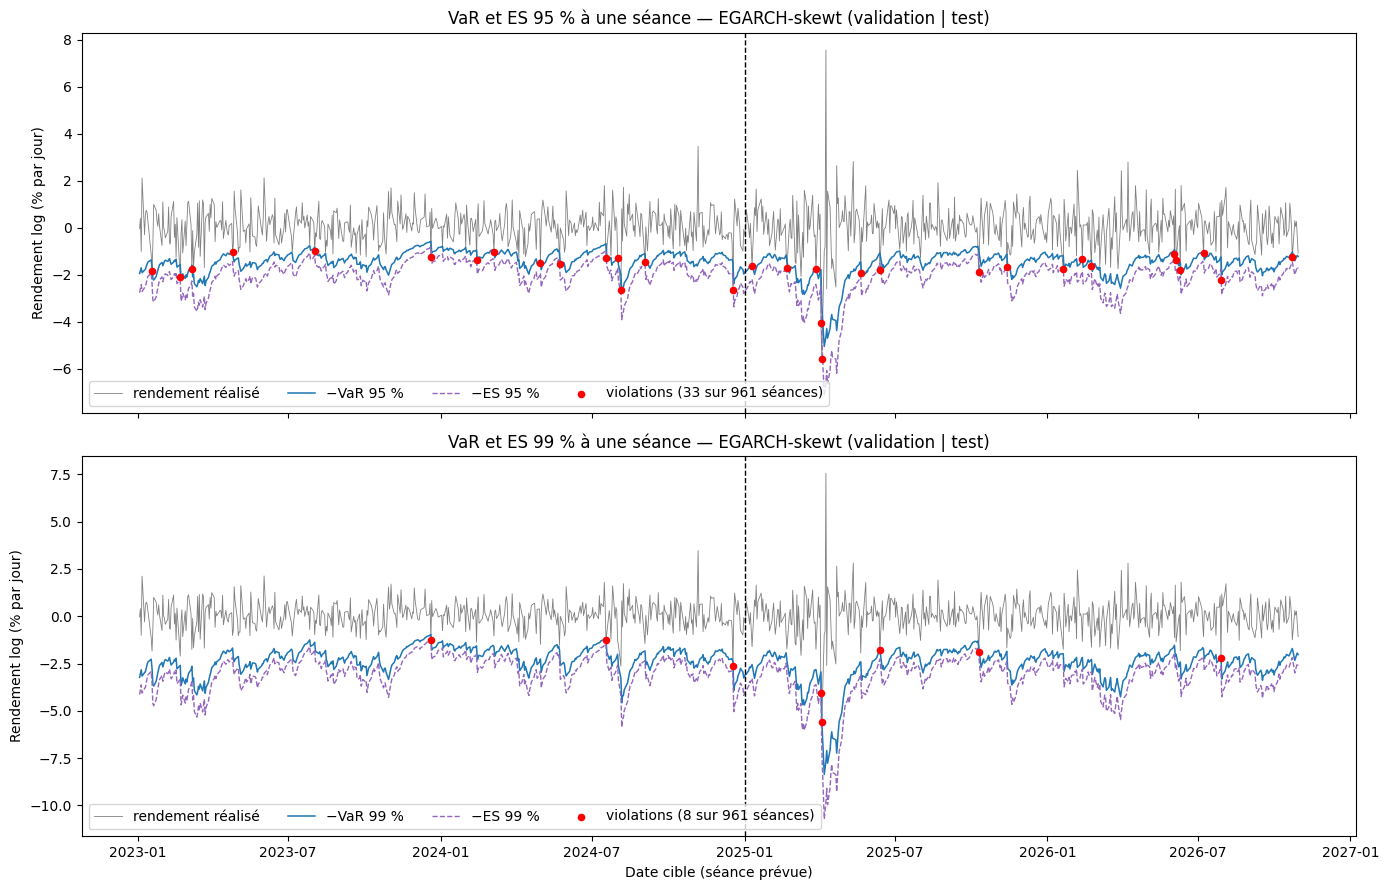

Figure sauvegardée : reports\d04\figures\var_es_violations.png
VaR et ES moyennes du modèle retenu (perte positive, une séance ; USD sur 100000 $) :


,fenetre,mesure,niveau,moyenne (% par jour),moyenne (USD),n
0,validation,VAR,95,1.35,1340,502
1,validation,ES,95,1.917,1898,502
2,validation,VAR,99,2.242,2215,502
3,validation,ES,99,2.878,2834,502
4,test,VAR,95,1.58,1566,459
5,test,ES,95,2.243,2214,459
6,test,VAR,99,2.622,2583,459
7,test,ES,99,3.365,3301,459


In [8]:
s_vt = m_ret['serie'].reindex(idx_vt)
r_vt = r.reindex(idx_vt)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for ax, niv in zip(axes, (95, 99)):
    viol = (r_vt < -s_vt[f'var{niv}_pct']).to_numpy()
    ax.plot(idx_vt, r_vt, color='grey', lw=0.6, label='rendement réalisé')
    ax.plot(idx_vt, -s_vt[f'var{niv}_pct'], color='#1f77b4', lw=1.1, label=f'−VaR {niv} %')
    ax.plot(idx_vt, -s_vt[f'es{niv}_pct'], color='#9467bd', lw=1.0, ls='--', label=f'−ES {niv} %')
    ax.scatter(idx_vt[viol], r_vt[viol], color='red', s=20, zorder=3,
               label=f'violations ({int(viol.sum())} sur {len(idx_vt)} séances)')
    ax.axvline(debut_test, color='black', ls='--', lw=1)
    ax.set_ylabel('Rendement log (% par jour)')
    ax.set_title(f'VaR et ES {niv} % à une séance — ' + NOM_RETENU + ' (validation | test)')
    ax.legend(loc='lower left', ncol=4)
axes[-1].set_xlabel('Date cible (séance prévue)')
plt.tight_layout()
fig.savefig(REP_FIG / 'var_es_violations.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figure sauvegardée :', (REP_FIG / 'var_es_violations.png').relative_to(root))

print('VaR et ES moyennes du modèle retenu (perte positive, une séance ; USD sur', CAPITAL, '$) :')
display(resume_var_moyenne(m_ret['serie'], fen_idx)
        .rename(columns={'moyenne_pct': 'moyenne (% par jour)', 'moyenne_usd': 'moyenne (USD)'}))

## 7. Tableaux de vérification VaR / ES

Pour la **validation** et le **test**, à 95 % et 99 %, quatre mesures : le modèle retenu, le GARCH(1,1) normal, l'EWMA RiskMetrics (λ = 0,94, loi normale) et la simulation historique (250 séances).

- `violations / jours`, `taux_observe_pct` contre `taux_attendu_pct` (en %).
- `kupiec_p` : couverture inconditionnelle (Kupiec, 1995), H0 = taux correct.
- `christoffersen_ind_p` : indépendance des violations (Christoffersen, 1998) ; `couverture_cond_p` : les deux à la fois, χ²(2).
- `es_moyen_prevu_pct` contre `perte_moyenne_realisee_pct` : moyennes sur les jours de violation, en % par jour.
- `z2`, `z2_p` : test de l'ES d'Acerbi & Székely (2014). Z2 < 0 = ES optimiste ; p-value unilatérale par 5 000 simulations sous la loi de chaque modèle (seed de frozen.yaml).
- `conclusion` au seuil de 5 %.

In [9]:
verif = tableau_verification(r, [m_ret, m_ref, m_ewma, m_hs], fen_idx)
for fen in fen_idx:
    for niv in (95, 99):
        print(f'=== Fenêtre {fen} — VaR / ES {niv} % ===')
        display(verif[(verif['fenetre'] == fen) & (verif['niveau'] == niv)]
                .drop(columns=['fenetre', 'niveau']).reset_index(drop=True))

=== Fenêtre validation — VaR / ES 95 % ===


,modele,jours,violations,taux_observe_pct,taux_attendu_pct,kupiec_p,christoffersen_ind_p,couverture_cond_p,es_moyen_prevu_pct,perte_moyenne_realisee_pct,z2,z2_p,conclusion
0,EGARCH-skewt,502,15,2.988,5,0.02582,0.3359,0.0525,1.705,1.577,0.4288,0.9866,rejetée : taux de violation rejeté (Kupiec)
1,GARCH-normal,502,23,4.582,5,0.6629,0.1367,0.3005,1.47,1.449,0.0976,0.6726,validée
2,EWMA,502,29,5.777,5,0.4352,0.7976,0.7137,1.393,1.42,-0.182,0.1664,validée
3,Simulation historique (250 j),502,17,3.386,5,0.07885,0.1225,0.06477,1.387,1.513,0.2421,0.9246,validée


=== Fenêtre validation — VaR / ES 99 % ===


,modele,jours,violations,taux_observe_pct,taux_attendu_pct,kupiec_p,christoffersen_ind_p,couverture_cond_p,es_moyen_prevu_pct,perte_moyenne_realisee_pct,z2,z2_p,conclusion
0,EGARCH-skewt,502,3,0.5976,1,0.3274,0.8492,0.6079,1.937,1.724,0.4534,0.8402,validée
1,GARCH-normal,502,5,0.996,1,0.9928,0.7509,0.9508,2.047,2.055,-0.01769,0.4264,validée
2,EWMA,502,6,1.195,1,0.6698,0.7029,0.849,1.785,1.96,-0.3059,0.24,validée
3,Simulation historique (250 j),502,6,1.195,1,0.6698,0.0538,0.1422,1.481,1.86,-0.4804,0.2724,validée


=== Fenêtre test — VaR / ES 95 % ===


,modele,jours,violations,taux_observe_pct,taux_attendu_pct,kupiec_p,christoffersen_ind_p,couverture_cond_p,es_moyen_prevu_pct,perte_moyenne_realisee_pct,z2,z2_p,conclusion
0,EGARCH-skewt,459,18,3.922,5,0.2713,0.732,0.515,1.978,1.977,0.2291,0.8608,validée
1,GARCH-normal,459,25,5.447,5,0.665,0.7661,0.8711,1.658,1.856,-0.2063,0.1496,validée
2,EWMA,459,25,5.447,5,0.665,0.5513,0.7624,1.617,1.863,-0.2394,0.1178,validée
3,Simulation historique (250 j),459,26,5.664,5,0.522,0.6625,0.7407,2.017,1.993,-0.1556,0.2854,validée


=== Fenêtre test — VaR / ES 99 % ===


,modele,jours,violations,taux_observe_pct,taux_attendu_pct,kupiec_p,christoffersen_ind_p,couverture_cond_p,es_moyen_prevu_pct,perte_moyenne_realisee_pct,z2,z2_p,conclusion
0,EGARCH-skewt,459,5,1.089,1,0.8496,0.0378,0.1136,3.543,3.106,0.03331,0.493,rejetée : violations groupées (Christoffersen)
1,GARCH-normal,459,8,1.743,1,0.1478,0.1204,0.105,2.328,2.577,-0.936,0.0334,rejetée : ES trop optimiste (Z2)
2,EWMA,459,8,1.743,1,0.1478,0.1204,0.105,2.088,2.619,-1.126,0.0164,rejetée : ES trop optimiste (Z2)
3,Simulation historique (250 j),459,7,1.525,1,0.294,0.08706,0.1334,2.297,2.725,-0.7479,0.1522,validée


## 8. Qualité de la volatilité prévue

Perte QLIKE moyenne (Patton, 2011, forme RV/h + ln h, sans unité ; plus petite = meilleure) contre la variance réalisée r² (%² par jour), sur les mêmes dates pour tous les modèles, en validation et sur le test. Les mesures complémentaires (MSE, Parkinson², Mincer-Zarnowitz, Diebold-Mariano) sont en annexe.

In [10]:
NOM_GLISS = 'Glissante ' + str(RCFG['rolling_window']) + ' j'
sigmas = {
    NOM_RETENU: m_ret['serie']['sigma_pct'],
    NOM_REF: m_ref['serie']['sigma_pct'],
    'EWMA': m_ewma['serie']['sigma_pct'],
    NOM_GLISS: rolling_sigma(r),
    'Écart-type historique': historical_sigma(r),
}
realisees = {'r²': r ** 2, 'Parkinson²': sigma_park ** 2}

eval_vol = tableau_volatilite(sigmas, realisees, fen_idx)        # détail en annexe
dm_vol = tableau_dm_volatilite(sigmas, realisees, fen_idx, reference=NOM_RETENU,
                               concurrents=['EWMA', NOM_GLISS, NOM_REF])   # détail en annexe

print('QLIKE moyenne contre r² (sans unité, plus petite = meilleure), triée sur le test :')
display(eval_vol[eval_vol['mesure_realisee'] == 'r²']
        .pivot(index='modele', columns='fenetre', values='qlike_moyen')[['validation', 'test']]
        .sort_values('test'))

QLIKE moyenne contre r² (sans unité, plus petite = meilleure), triée sur le test :


fenetre,validation,test
modele,,
EGARCH-skewt,0.3692,0.6443
GARCH-normal,0.3674,0.6863
EWMA,0.3574,0.7304
Glissante 20 j,0.3993,0.7916
Écart-type historique,0.8199,0.9836


## 9. Coût de calcul (axe B09)

Temps d'estimation sur l'apprentissage et temps de prévision à un pas sur toute la série, en secondes (`time.perf_counter`). Les baselines n'ont pas d'estimation. Les durées varient légèrement d'une exécution à l'autre.

In [11]:
temps = tableau_temps(fits, r)
display(temps.rename(columns={'estimation_s': 'estimation (s)', 'prevision_s': 'prévision (s)',
                              'total_s': 'total (s)'}))

,modele,estimation (s),prévision (s),total (s)
0,GJR-GARCH-skewt,0.05358,0.00452,0.0581
1,EGARCH-skewt,0.04703,0.004266,0.0513
2,GARCH-skewt,0.04256,0.003563,0.04612
3,GJR-GARCH-t,0.03532,0.003719,0.03904
4,GARCH-t,0.02938,0.00334,0.03272
5,EGARCH-t,0.02656,0.004219,0.03078
6,GJR-GARCH-normal,0.02471,0.004126,0.02884
7,EGARCH-normal,0.02248,0.00438,0.02686
8,Simulation historique (250 j),0,0.02666,0.02666
9,GARCH-normal,0.02016,0.003424,0.02358


## 9b. Sauvegarde du modèle retenu et risque de la prochaine séance

Le modèle retenu (type, loi, paramètres gelés, période d'apprentissage) est écrit dans `models/risk_params.json`. L'application (D07), la stratégie (D06) et le paper trading (D08) le rechargent sans ré-estimer. Démonstration « comme dans l'app » : `risk_today` pour la dernière date du snapshot.

In [12]:
chemin_modele = save_risk_model(fit_ret['spec'], fit_ret['params'])
modele = load_risk_model(chemin_modele)
print('Modèle sauvegardé :', chemin_modele.relative_to(root))
print('  type :', modele['nom'], '| apprentissage :', modele['periode_apprentissage'],
      '| arch', modele['arch_version'])

demain = risk_today(r, chemin_modele)
unites = {'modele': '', 'capital': 'USD', 'date_prevision': 'date', 'date_cible': 'date',
          'mu_pct': '% par jour', 'sigma_pct': '% par jour', 'sigma_annuelle_pct': '% par an (× √252)'}
display(pd.DataFrame({'séance suivante': pd.Series(demain),
                      'unité': pd.Series({k: unites.get(k, 'USD' if k.endswith('_usd') else '% par jour, perte positive')
                                         for k in demain})}))

Modèle sauvegardé : models\risk_params.json
  type : EGARCH-skewt | apprentissage : ['2018-01-01', '2022-12-31'] | arch 9.0.0


,séance suivante,unité
modele,EGARCH-skewt,
capital,1e+05,USD
date_prevision,2026-10-30 00:00:00,date
date_cible,2026-11-02 00:00:00,date
mu_pct,0.0196,% par jour
sigma_pct,0.8869,% par jour
sigma_annuelle_pct,14.08,% par an (× √252)
var95_pct,1.506,"% par jour, perte positive"
es95_pct,2.139,"% par jour, perte positive"
var99_pct,2.501,"% par jour, perte positive"


## 10. Exports `reports/d04/`

In [13]:
risque_date = tableau_risque_date(r, m_ret['serie'], sigma_park, fen_idx)
exports = {
    'arch_lm.csv': df_arch,
    'grille_modeles.csv': grille,
    'parametres_retenu.csv': tableau_parametres(fit_ret),
    'diagnostics_residus_std.csv': diag_z,
    'verification_var_es.csv': verif,
    'eval_volatilite.csv': eval_vol,
    'dm_volatilite.csv': dm_vol,
    'temps_calcul.csv': temps,
    'risque_date.csv': risque_date,
}
for nom, df in exports.items():
    df.to_csv(REP_D04 / nom, index=False)
    print(f'{nom:<30} {df.shape[0]:>5} lignes × {df.shape[1]:>2} colonnes')
display(risque_date.head())

arch_lm.csv                        4 lignes ×  6 colonnes
grille_modeles.csv                 9 lignes × 14 colonnes
parametres_retenu.csv              7 lignes ×  5 colonnes
diagnostics_residus_std.csv        9 lignes ×  5 colonnes
verification_var_es.csv           16 lignes × 15 colonnes
eval_volatilite.csv               20 lignes × 10 colonnes
dm_volatilite.csv                 12 lignes ×  8 colonnes
temps_calcul.csv                  12 lignes ×  4 colonnes
risque_date.csv                  961 lignes × 13 colonnes


,date_prevision,date_cible,fenetre,rendement_realise_pct,sigma_pct,sigma_parkinson_pct,var95_pct,es95_pct,var99_pct,es99_pct,var95_usd,violation95,violation99
0,2022-12-30,2023-01-03,validation,-0.03319,1.143,0.994,1.947,2.762,3.229,4.142,1928,0,0
1,2023-01-03,2023-01-04,validation,0.4037,1.072,0.6944,1.826,2.59,3.028,3.885,1809,0,0
2,2023-01-04,2023-01-05,validation,-1.009,1.002,0.5557,1.705,2.419,2.828,3.629,1690,0,0
3,2023-01-05,2023-01-06,validation,2.122,1.121,1.298,1.909,2.708,3.166,4.061,1891,0,0
4,2023-01-06,2023-01-09,validation,-0.2948,1.055,0.7998,1.796,2.549,2.98,3.823,1780,0,0


## 11. Conclusion

1. **Effet ARCH confirmé.** Sur l'apprentissage, l'ARCH-LM à 5 retards rejette l'absence d'effet ARCH sur les rendements centrés (LM = 461.2, p = 1.867e-97) comme sur les résidus de l'ARIMA(0,0,3) de D03 (LM = 315.6, p = 4.523e-66). Le risque se prévoit, même si la direction ne se prévoit pas (D03).

2. **Asymétrie utile.** Une baisse est suivie d'une volatilité plus forte qu'une hausse (corrélation entre r_t et |r_{t+1}| : −0.1129, p = 5.99e-05). Pour chaque loi, GJR-GARCH et EGARCH ont un AIC plus faible que le GARCH symétrique (loi normale : 3622 pour GARCH, 3591 pour GJR, 3585 pour EGARCH).

3. **Modèle retenu : EGARCH-skewt** (plus petit AIC d'apprentissage, 3502). Sa loi Student asymétrique a des queues épaisses (η = 6.851) et une queue gauche plus lourde (λ = −0.2049), et le QQ-plot la montre bien plus proche des résidus que la loi normale.

4. **Persistance élevée.** β = 0.9728 : un choc de volatilité met 25.11 séances, environ cinq semaines, à se résorber de moitié (23.22 séances pour le GARCH normal).

5. **Résidus presque propres.** Il ne reste pas d'autocorrélation dans z (Ljung-Box, p = 0.8415, 0.2205, 0.6391 à 5, 10, 20 retards). Un petit effet ARCH de court terme subsiste (ARCH-LM sur z : p = 0.004325 à 5 retards, 0.04234 à 10), sans commune mesure avec l'effet brut (LM = 17.09 contre 461.2).

6. **VaR validée dans deux cas sur quatre ; ES jamais optimiste.**

   | Fenêtre · niveau | Violations | Kupiec p | Christoffersen p | Verdict |
   |:--|--:|--:|--:|:--|
   | Validation · 95 % | 15 / 502 (2.988 %) | 0.02582 | 0.3359 | rejetée : trop **peu** de violations |
   | Validation · 99 % | 3 / 502 (0.5976 %) | 0.3274 | 0.8492 | validée |
   | Test · 95 % | 18 / 459 (3.922 %) | 0.2713 | 0.732 | validée |
   | Test · 99 % | 5 / 459 (1.089 %) | 0.8496 | 0.0378 | rejetée : violations **groupées** |

   Z2 est positif dans les quatre cas, donc l'ES n'est jamais trop optimiste ; à 99 % sur le test, les modèles à loi normale le sont (Z2 p = 0.0334 pour le GARCH normal, 0.0164 pour l'EWMA).

7. **Complexe contre simple (B09).** Pour la VaR, la simulation historique, sans paramètre estimé, est validée dans les quatre cas, contre deux pour l'EGARCH-skewt. Pour la volatilité prévue, l'EGARCH-skewt a la plus petite QLIKE sur le test (0.6443) mais pas en validation (0.3692 contre 0.3574 pour l'EWMA), pour un coût de calcul négligeable (moins d'un dixième de seconde, section 9) : la complexité se justifie pour prévoir σ, pas pour la VaR.

8. **Lien D06 et limites.** `risk_today` fournit à la stratégie, sans ré-estimation, la σ prévue pour le 2026-11-02 (0.8869 % par jour) et la VaR 95 % (1.506 %, soit 1495 USD sur 100 000 $), qui serviront à réduire la position quand le risque monte. Limites : paramètres gelés sur 2018–2022, période qui contient le COVID (d'où la VaR 95 % trop prudente en validation), horizon d'une seule séance, et risque mesuré de clôture à clôture alors que D06 exécute à l'ouverture de t+1.

## Annexe — analyses complémentaires

### Qualité de la volatilité prévue : MSE, Parkinson², Mincer-Zarnowitz, Diebold-Mariano

Pertes moyennes **QLIKE** (Patton, 2011, forme RV/h + ln h : plus petit = meilleur, robuste au bruit de la mesure réalisée) et **MSE** (%⁴), contre deux variances réalisées : r² et Parkinson² (%² par jour). Tous les modèles sont comparés sur les mêmes dates.
**Mincer-Zarnowitz** : RV = a + b·σ² ; une prévision sans biais a a = 0 et b = 1 (`mz_p` = p-value du test joint, écarts-types de Newey-West). Parkinson² est structurellement plus basse que r² (elle ignore l'écart de nuit). QLIKE et MSE étant minimales quand la prévision égale l'espérance de la mesure réalisée, une mesure biaisée vers le bas favorise les prévisions de niveau bas : les classements contre Parkinson² sont donc donnés à titre indicatif, et la **référence est r²**, sans biais mais bruitée.
**Diebold-Mariano** sur les pertes QLIKE (variance de Newey-West, correction HLN) : modèle retenu contre EWMA, contre l'écart-type glissant et contre le GARCH normal ; `mean_d` < 0 = modèle retenu meilleur.

In [14]:
for fen in fen_idx:
    for rv in realisees:
        print(f'=== Fenêtre {fen} — variance réalisée {rv} (%² par jour) ===')
        display(eval_vol[(eval_vol['fenetre'] == fen) & (eval_vol['mesure_realisee'] == rv)]
                .drop(columns=['fenetre', 'mesure_realisee']).sort_values('qlike_moyen')
                .reset_index(drop=True))

print('=== Diebold-Mariano sur QLIKE ===')
display(dm_vol)

=== Fenêtre validation — variance réalisée r² (%² par jour) ===


,modele,qlike_moyen,mse_moyen,mz_a,mz_b,mz_r2,mz_p,n
0,EWMA,0.3574,0.9127,0.3473,0.3151,0.005329,0.0002952,502
1,GARCH-normal,0.3674,0.9934,0.3816,0.1913,0.004433,5.837e-13,502
2,EGARCH-skewt,0.3692,0.9521,0.2404,0.4018,0.02714,2.362e-11,502
3,Glissante 20 j,0.3993,0.9302,0.3864,0.2458,0.00471,2.453e-06,502
4,Écart-type historique,0.8199,2.245,0.3462,0.1004,0.0001586,8.257e-108,502


=== Fenêtre validation — variance réalisée Parkinson² (%² par jour) ===


,modele,qlike_moyen,mse_moyen,mz_a,mz_b,mz_r2,mz_p,n
0,EWMA,0.0306,0.1789,0.14,0.43,0.0608,1.536e-12,502
1,Glissante 20 j,0.04649,0.2007,0.2254,0.2736,0.03574,3.313e-13,502
2,EGARCH-skewt,0.0932,0.2815,0.1112,0.3764,0.1459,4.785e-55,502
3,GARCH-normal,0.1193,0.2994,0.1743,0.279,0.05776,9.286e-44,502
4,Écart-type historique,0.7304,1.849,-0.2313,0.3583,0.01237,1.707e-210,502


=== Fenêtre test — variance réalisée r² (%² par jour) ===


,modele,qlike_moyen,mse_moyen,mz_a,mz_b,mz_r2,mz_p,n
0,EGARCH-skewt,0.6443,9.224,-0.2988,1.206,0.1466,0.1204,459
1,GARCH-normal,0.6863,10.27,0.2593,0.6181,0.07468,0.2148,459
2,EWMA,0.7304,10.42,0.2877,0.6713,0.03948,0.1226,459
3,Glissante 20 j,0.7916,11.1,0.5373,0.3903,0.02275,0.0001359,459
4,Écart-type historique,0.9836,11.04,-7.319,5.65,0.0061,3.928e-18,459


=== Fenêtre test — variance réalisée Parkinson² (%² par jour) ===


,modele,qlike_moyen,mse_moyen,mz_a,mz_b,mz_r2,mz_p,n
0,EGARCH-skewt,0.337,2.112,-0.4511,1.059,0.3833,8.888e-20,459
1,GARCH-normal,0.3439,2.919,-0.02341,0.6033,0.2413,1.461e-11,459
2,EWMA,0.3619,3.161,0.09599,0.5538,0.09112,0.0004408,459
3,Glissante 20 j,0.3663,3.825,0.2977,0.3265,0.05399,0.002083,459
4,Écart-type historique,0.7799,3.887,-5.563,4.238,0.01164,1.831e-111,459


=== Diebold-Mariano sur QLIKE ===


,fenetre,mesure_realisee,comparaison,dm_stat,pval,mean_d,n,conclusion
0,validation,r²,EGARCH-skewt vs EWMA,0.263,0.7927,0.0118,502,pas de différence significative
1,validation,r²,EGARCH-skewt vs Glissante 20 j,-0.7134,0.4759,-0.03014,502,pas de différence significative
2,validation,r²,EGARCH-skewt vs GARCH-normal,0.04382,0.9651,0.001735,502,pas de différence significative
3,validation,Parkinson²,EGARCH-skewt vs EWMA,2.958,0.003242,0.0626,502,EWMA meilleur
4,validation,Parkinson²,EGARCH-skewt vs Glissante 20 j,1.987,0.04743,0.04671,502,Glissante 20 j meilleur
5,validation,Parkinson²,EGARCH-skewt vs GARCH-normal,-1.287,0.1987,-0.0261,502,pas de différence significative
6,test,r²,EGARCH-skewt vs EWMA,-2.006,0.04548,-0.08606,459,EGARCH-skewt meilleur
7,test,r²,EGARCH-skewt vs Glissante 20 j,-2.611,0.009329,-0.1473,459,EGARCH-skewt meilleur
8,test,r²,EGARCH-skewt vs GARCH-normal,-2.007,0.0453,-0.04203,459,EGARCH-skewt meilleur
9,test,Parkinson²,EGARCH-skewt vs EWMA,-0.7972,0.4258,-0.0249,459,pas de différence significative


## Références

- Acerbi, C. & Székely, B. (2014). Backtesting Expected Shortfall. *Risk*, décembre 2014.
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.
- Glosten, L. R., Jagannathan, R. & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *Journal of Finance*, 48(5), 1779–1801.
- Hansen, B. E. (1994). Autoregressive conditional density estimation. *International Economic Review*, 35(3), 705–730.
- J.P. Morgan / Reuters (1996). *RiskMetrics — Technical Document*, 4e édition.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- Nelson, D. B. (1991). Conditional heteroskedasticity in asset returns: a new approach. *Econometrica*, 59(2), 347–370.
- Parkinson, M. (1980). The extreme value method for estimating the variance of the rate of return. *Journal of Business*, 53(1), 61–65.
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256.